<a href="https://colab.research.google.com/github/JuanFerMC/Labs-Model-and-Sim-Sist/blob/main/lab5_parte1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 5 - Parte 1. Redes recurrentes

## Objetivo general

En este laboratorio el estudiante entrenará una Red Neuronal Recurrente (RNN) para resolver un problema de predicción de series de tiempo, y comparará su desempeño con un Perceptrón Multicapa (MLP). Al finalizar, también implementará una red LSTM y observará sus ventajas frente a la RNN simple.

El laboratorio está organizado en cinco ejercicios:

| Ejercicio | Tarea principal |
|-----------|-----------------|
| 1 | Explorar la serie de tiempo mediante autocorrelación y transformar los datos al formato `(X, Y)` requerido por la RNN |
| 2 | Construir la arquitectura RNN en PyTorch |
| 3 | Experimentar variando el número de retardos y neuronas ocultas en la RNN |
| 4 | Resolver el mismo problema con un MLP y comparar resultados |
| 5 | Construir una arquitectura LSTM y evaluar sus ventajas |

---

## Fundamento teórico: series de tiempo y RNN

Una **serie de tiempo** es una secuencia de observaciones ordenadas en el tiempo. Para predecir el valor siguiente se asume que los valores pasados contienen información relevante. El número de valores pasados que se incluyen como entrada se denomina **retardo** (*lag* o *look-back*).

La configuración usada en este laboratorio es **many-to-one**: varios pasos de tiempo pasados → un único valor futuro.

Una **Red Neuronal Recurrente (RNN)** mantiene un estado oculto `h_t` que actúa como memoria:

```
h_t = tanh(W_hx · x_t + W_hh · h_{t-1} + b_h)
y_t = W_yh · h_t + b_y
```

Los pesos se comparten en todos los pasos de tiempo, lo que permite aprender patrones en secuencias de longitud variable.

**Problema del gradiente evanescente:** en secuencias largas, los gradientes que viajan hacia atrás en el tiempo se vuelven muy pequeños y la RNN simple "olvida" el contexto lejano. La solución son las redes **LSTM** y **GRU**, que incorporan compuertas de memoria explícitas.

---

## Configuración del entorno

Las siguientes celdas descargan las dependencias e inicializan la sesión. Deben ejecutarse en orden antes de comenzar los ejercicios.

> **Nota:** la celda de login solicitará las credenciales institucionales del estudiante.

In [2]:
!wget -nc --no-cache -O init.py -q https://raw.githubusercontent.com/jdariasl/Intro_ML_2025/master/init.py
import init; init.init(force_download=False); init.get_weblink()

replicating local resources
replicating Labs resources


In [17]:
from local.lib.rlxmoocapi import submit, session
import inspect
session.LoginSequence(endpoint=init.endpoint, course_id=init.course_id, lab_id="L05.01", varname="student");

logging in as juanf.mona@udea.edu.co... please wait

-------------
using course session introml::udea.vir.20262.g2
success!! you are logged in
-------------


In [4]:
#configuración del laboratorio
# Ejecuta esta celda!
from Labs.commons.utils.lab5 import *
_, dataset = part_1()

En este  laboratorio entrenaremos una Red Neuronal Recurrente para la predicción de una serie de tiempo.

Este problema corresponde a una configuración many-to-one.

En este caso usaremos una serie de tiempo que corresponde al número de pasajeros internacionales por mes, desde el año 1949 hasta el año 1960.

En la siguiente celda visualizamos los datos.

Debemos observar el aparente periodo que existe en nuestra variable. ¿cada cuantos meses parece repertirse el patrón de la serie?

## Conjunto de datos: pasajeros aéreos internacionales

Se trabaja con la serie clásica **International Airline Passengers** (Box & Jenkins, 1976), que registra el número mensual de pasajeros internacionales desde enero de 1949 hasta diciembre de 1960 (144 observaciones).

Características clave de la serie:
- **Tendencia creciente:** el número de pasajeros aumenta con el tiempo.
- **Estacionalidad anual:** existe un patrón que se repite cada 12 meses (picos en verano del hemisferio norte).
- **Escala variable:** la amplitud de las oscilaciones crece con el nivel de la serie (estacionalidad multiplicativa).

Antes de entrenar cualquier modelo, es fundamental **normalizar** la serie al rango `[0, 1]` con `MinMaxScaler`. Esto es especialmente importante para redes neuronales, que son sensibles a la magnitud de los valores de entrada.

> **La siguiente celda visualiza la serie. Observe el patrón periódico y estime visualmente cada cuántos meses se repite.**

tenemos dispnible nuestra base de datos en el pandas DF 'dataset' 



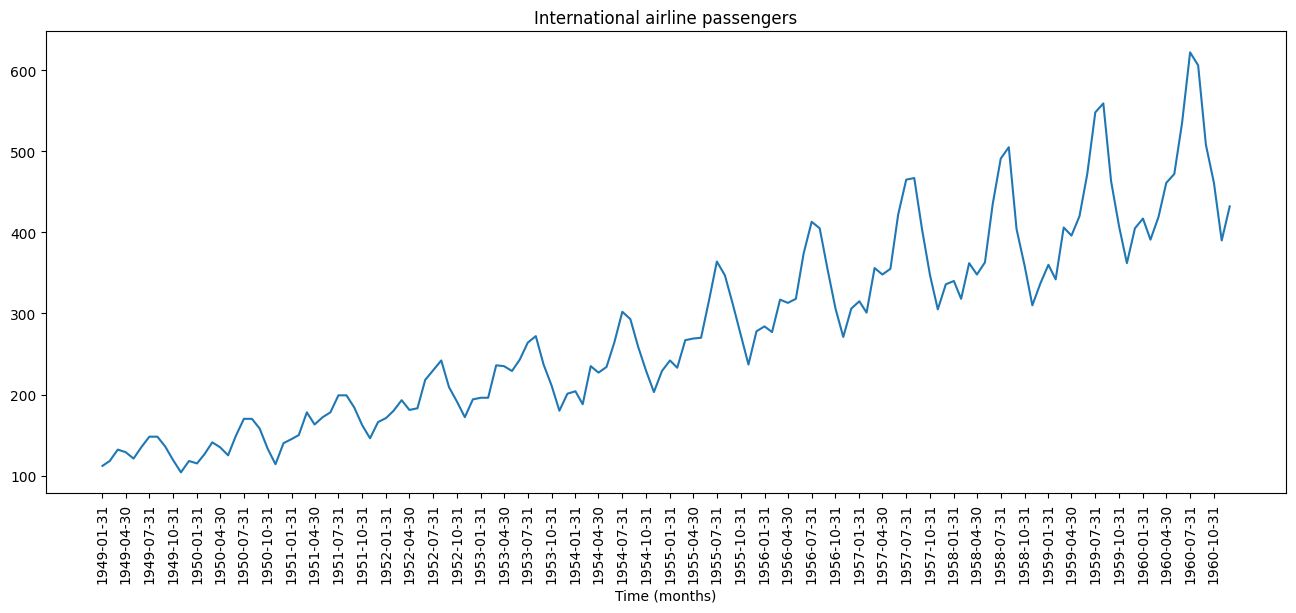

In [5]:
# creamos una variable para
# el tiempo
Time = pd.date_range(np.datetime64('1949-01'), np.datetime64('1961-01'), freq='M')
print("tenemos dispnible nuestra base de datos en el pandas DF 'dataset' \n")
fig, ax = plt.subplots(figsize = (16,6))
ax.plot(Time,dataset)
ax.set_title('International airline passengers')
ax.set_xlabel('Time (months)')
ax.set_xticks( pd.date_range(np.datetime64('1949-01'), np.datetime64('1961-01'), freq='3M'))
plt.xticks(rotation=90)
plt.show()

En nuestro primer ejercicio vamos a explorar, el patrón que observamos en la grafica anterior. Esto también nos puede decir qué relación existe entre una muestra en el tiempo $t$ con las muestras anteriores.

La libreria statsmodel [tiene una función que nos sirve para analizar esta relación](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html).


## Ejercicio 1 - Exploración del problema

Este plot realiza una operación cuyos detalles son explicados en mayor profundidad en [esta buena entrada de blog](https://machinelearningmastery.com/gentle-introduction-autocorrelation-partial-autocorrelation/). Pero en este laboratorio lo que no interesa entender es:

1. El valor varia entre 1.0 y -1.0.
2. Cuando el valor de la correlación es 1.0, corresponde el valor maximo indicando una relación positiva entre la variable y su correspondiente lag o retraso.
3. Cuando el valor de la correlación es -1.0, corresponde el valor mínimo indicando una relación negativa entre la variable y su correspondiente lag o retraso..
4. 0.0 indica que los valores no están relacionados.
5. el lag indica, el número de retrasos. Si el valor de la correlación en el lag  5 es igual 0.75, indica una relación positiva alta entre el actaul y el quinto retraso anterior en la mayoria de muestras de nuestra variable de respuesta.

Ahora, grafiquemos la correlación para un maximo de 36 lags de nuestros datos. Esto significa que estamos analizando las relación de una muestras respecto a la 36 muestras pasdas.

Sabiendo que nuestro eje X representa los meses y nuestro eje y representan el número de pasajeros. Al realizar el analisis de lags estamos determinando si el número de pasajeros de los meses pasados tiene influencia en el nuúmero de pasajeros en el mes acutal.

---

## Ejercicio 1: exploración del problema y transformación de datos

### Concepto: autocorrelación

La **función de autocorrelación (ACF)** mide la correlación de la serie consigo misma con distintos retardos. Para el retardo `k`, la autocorrelación es:

`ACF(k) = Cov(y_t, y_{t-k}) / Var(y_t)`

Un valor cercano a **1.0** indica correlación positiva fuerte con ese retardo (el valor actual es muy similar al valor `k` pasos atrás). Un valor cercano a **0** indica independencia.

**Cómo usar la ACF para elegir el `look_back`:** los picos significativos en la ACF indican retardos relevantes. En una serie con periodicidad anual (12 meses), se esperan picos en los retardos 12, 24, 36, etc. Esto sugiere que incluir al menos 12 retardos como entrada puede capturar el patrón estacional.

La región sombreada en la gráfica marca el **intervalo de confianza al 95%**: retardos cuya barra cae dentro de esa zona no son estadísticamente significativos.

> **Observe la gráfica y preste atención a las marcas rojas (retardos múltiplos de 12). Eso respaldará la respuesta a la pregunta abierta.**

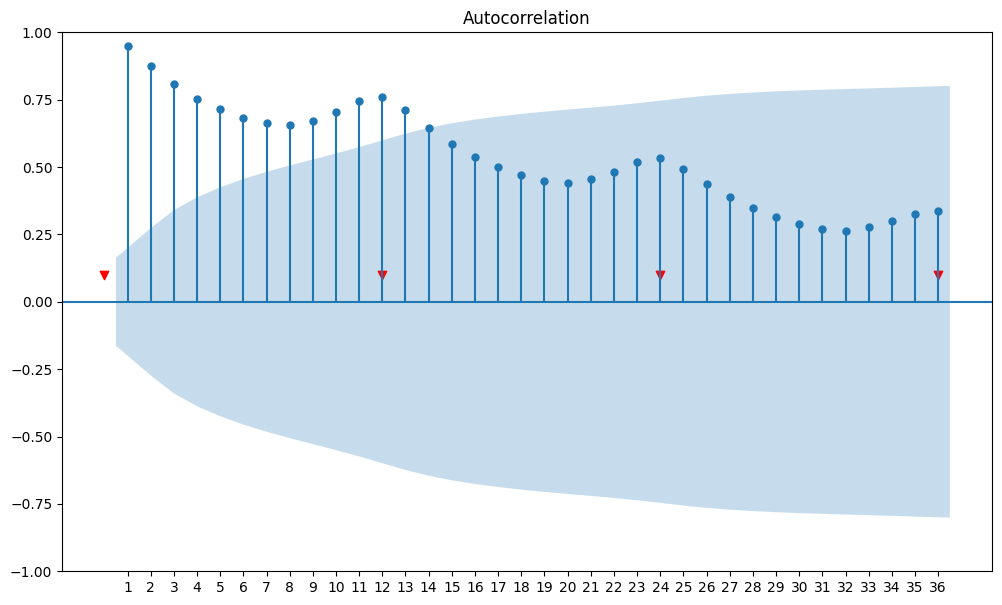

In [6]:
from statsmodels.graphics import tsaplots
fig, ax = plt.subplots(figsize = (12,7))
# Display the autocorrelation plot of your time series
fig = tsaplots.plot_acf(dataset.passengers, lags=range(1,37), ax = ax)
ax.set_xticks( range(1,37))
ax.scatter(range(0,37,12), 0.1*np.ones(4), c = 'r', marker = "v")
plt.show()

reforzando el entendimiento, observando la grafica anterior:

1. Cuando hay un lag = 5 (es decir se evalúa qué tan relacionadas están las 5 muestras anteriores), tenemos una autocorrelación $\approx$ 0.75
2. Cuando hay un lag = 25 (es decir se evalúa qué tan relacionadas están las 25 muestras anteriores), tenemos una autocorrelación $\approx$ 0.5
3. Presta atención al patrón que se resalta con las marcas rojas

Vamos a observar estas relaciones viendo cómo los picos de correlación se relacionan con los patrones que vemos. A continuación, graficamos los valores de autocorrelación junto con la serie de los valores reales.

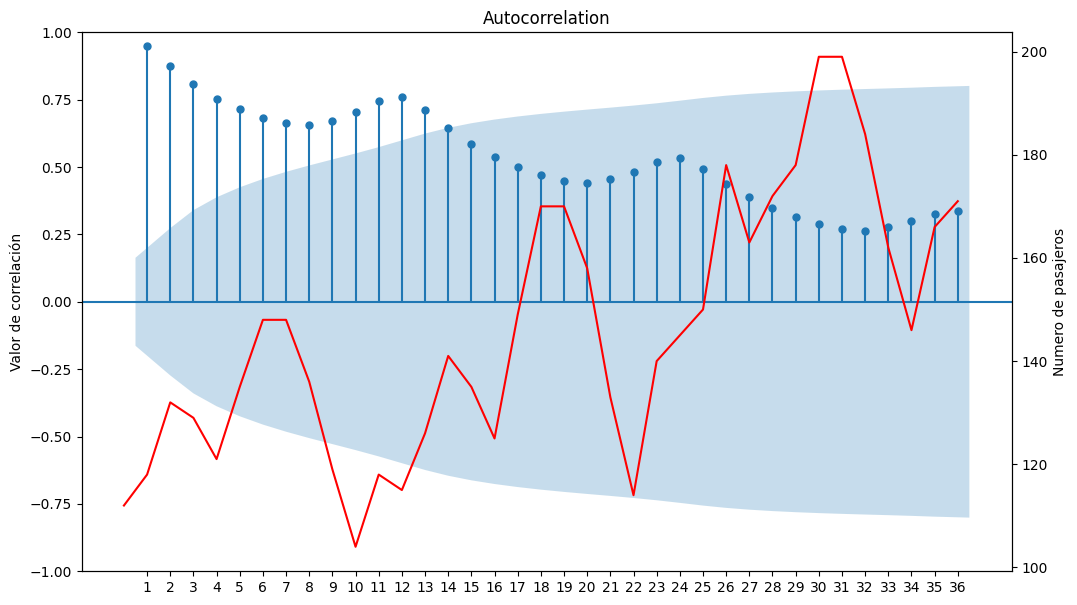

In [7]:
fig, ax = plt.subplots(figsize = (12,7))
# Display the autocorrelation plot of your time series
fig = tsaplots.plot_acf(dataset.passengers, lags=range(1,37), ax = ax)
ax.set_xticks( range(1,37))
ax.set_ylabel("Valor de correlación")
ax2 = ax.twinx()
ax2.set_ylabel("Numero de pasajeros")
ax2.plot(dataset[0:37], c = 'r')
plt.show()

Ahora bien, para poder aplicar una RNN, debemos transformar los datos. Observa la figura, para entender como debemos transformar los datos.

![rnn](https://raw.githubusercontent.com/jdariasl/ML_2020/master/Labs/commons/images/UDEA%20-%20RNN.jpg)

Con base en el análisis de correlación que reveló cómo están  relacionadas la muestra actual y las anteriores y teniendo en cuenta que la preparación de los datos consiste en usar las muestras pasadas para predicir la muestra siguiente. Responde la siguiente pregunta.

### Pregunta conceptual: número máximo de retardos

Antes de programar, reflexione sobre la relación entre la longitud de la serie, el `look_back` y la cantidad de muestras disponibles para entrenar. Si la serie tiene `N` puntos y usamos `look_back = k`, el número de muestras resultantes es `N - k`. Un valor de `k` muy grande reduce drásticamente los datos disponibles para entrenar. La gráfica de ACF le dará una cota teórica superior del `look_back` útil.

In [ ]:
#@title Pregunta Abierta
#@markdown ¿Cual podría ser el número máximo de muestras pasadas para transformar el conjunto de datos?
respuesta = "" #@param {type:"string"}

### Implementación: función `create_dataset`

#### Qué debe programar el estudiante

Esta función convierte la serie de tiempo en un conjunto de datos supervisado `(X, Y)`:

- **Entrada `X`:** matriz donde cada fila contiene los `look_back` valores anteriores al punto que se quiere predecir. Si `look_back = 3` y la serie es `[a, b, c, d, e, ...]`, la primera fila de `X` es `[a, b, c]` y el primer valor de `Y` es `d`.
- **Salida `Y`:** vector con el valor siguiente a cada ventana.

**Pasos a implementar:**
1. Crear listas vacías para acumular filas de `X` e `Y`.
2. Iterar `i` desde `0` hasta `len(dataset) - look_back - 1`.
3. En cada iteración, extraer la ventana `dataset[i : i + look_back, 0]` y añadirla a `X`; añadir `dataset[i + look_back, 0]` a `Y`.
4. Convertir ambas listas a arrays de NumPy y retornarlas.

> **Importante:** el `dataset` que llega a esta función es una matriz NumPy de forma `(N, 1)` (una columna). Por eso se indexa con `[:, 0]` para extraer el vector unidimensional.

Ahora, realicemos el ejercicio de transformar nuestros datos a la forma requerida.

In [36]:
def create_dataset(dataset, look_back=1):
    """función que crea dataset apto para RNN

    dataset: matriz numpy con el conjunto de datos
    look_back: número de retrasos con los cuales queremos construir
        las características

    Retorna:
      X: un numpy array con los valores de entrada a la red (debe ser una matrix)
      Y: un numpy array con los valores de salida deseada de la red
    """
    # Aseguramos que dataset sea un array de numpy
    data = np.asarray(dataset)
    # Si es unidimensional, lo convertimos a bidimensional (N, 1)
    if len(data.shape) == 1:
        data = data.reshape(-1, 1)

    X, Y = [], []
    for i in range(len(data) - look_back - 1):
        X.append(data[i:(i + look_back), 0])
        Y.append(data[i + look_back, 0])

    return np.array(X), np.array(Y)

**Registra tu solución en línea**

In [34]:
student.submit_task(namespace=globals(), task_id='T1');

In [37]:
# observemos el funcionamiento de nuestra funcion
x_to_see, y_to_see =  create_dataset(dataset.values, 3)
display("primeras muestras de x", x_to_see[0:3])
display("primeras muestras de y", y_to_see[0:3])

'primeras muestras de x'

array([[112, 118, 132],
       [118, 132, 129],
       [132, 129, 121]])

'primeras muestras de y'

array([129, 121, 135])

## Ejercicio 2 - Crear una RNN

Al igual que en laboratorio anterior, vamos a usar [PyTorch](https://pytorch.org/) para diseñar y construir las redes neuronales con las que vamos a experimentar.

En el siguiente ejercicio vamos a crear una función para construir una RNN usando la libreria mencionada.  Deben revisar con detenimiento la documentación de las capas tipo [RNN](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html).

### Concepto: arquitectura de una RNN en PyTorch

En PyTorch, una RNN se construye heredando de `nn.Module` y definiendo dos métodos:

- `__init__`: donde se declaran las capas como atributos del objeto.
- `forward`: donde se define el flujo de datos a través de las capas.

La capa `nn.RNN` recibe tres argumentos fundamentales:
- `input_size`: dimensión de cada vector de entrada `x_t`. Como la serie es unidimensional, `input_size = 1`.
- `hidden_size`: número de neuronas en el estado oculto (la "memoria" de la red).
- `batch_first=True`: si es `True`, la entrada tiene forma `(batch, tiempo, features)`, que es el convenio más intuitivo.

**Salidas de `nn.RNN`:** la capa retorna una tupla `(out, h_n)`:
- `out`: tensor con **todos** los estados ocultos `h_0, h_1, ..., h_T`. Forma: `(batch, seq_len, hidden_size)`.
- `h_n`: **solo** el último estado oculto `h_T`. Forma: `(num_layers, batch, hidden_size)`.

En este ejercicio se usa `h_n` (el último estado) porque el problema es **many-to-one**: solo interesa la predicción al final de la secuencia.

### Implementación: función `create_rnn_model`

#### Qué debe programar el estudiante

Dentro de la clase `Recurrent_NN`:

1. **`self.rnn`**: instanciar `nn.RNN` con `input_size=1`, `hidden_size=num_hidden_neurons` y `batch_first=True`.
2. **`self.linear`**: instanciar `nn.Linear` con `in_features=num_hidden_neurons` y `out_features=1` (una sola predicción numérica).

El método `forward` ya está implementado: extrae `h_n`, elimina la dimensión de `num_layers` con `.squeeze()` y pasa el resultado por la capa lineal.

> **Nota sobre `batch_first`:** si no se especifica `batch_first=True`, PyTorch espera entradas de forma `(seq_len, batch, features)`. En este laboratorio los datos se preparan con `batch_first=True`, así que es imprescindible incluirlo al instanciar `nn.RNN`.

In [55]:

# Vamos a crear una red neuronal recurrente. En este caso no podemos usar el módulo
# nn.Sequential porque las capas RNN retornan dos salidas y es necesario, según el
# diseño de la arquitectura, decidir cómo usarlas.
def create_rnn_model(num_hidden_neurons):
    """función que crea un modelo RNN
    La arquitectura de la red RNN debe estar compuesta de dos capas:
      1. Una capa RNN (tener en cuenta el número de neuronas ocultas,
         como vamos a modelar una serie temporal unidimensional, el número de características es 1)
      2. Una capa Densa (Linear) de salida

    parametros
      num_hidden_neurons (int): número neuronas en la capa oculta

    retorna nn.Module con la red neuronal
    """

    class Recurrent_NN(nn.Module):
      def __init__(self, num_hidden_neurons):
          super().__init__()
          self.rnn = nn.RNN(input_size=1, hidden_size=num_hidden_neurons, batch_first=True)
          self.linear = nn.Linear(in_features=num_hidden_neurons, out_features=1)

      #Este método define el fluje de información a través del modelo
      def forward(self, x):
          _, h = self.rnn(x)
          x = h.squeeze(0) # elimina la dimensión de la capa (num_layers=1)
          x = self.linear(x)
          return x

    return Recurrent_NN(num_hidden_neurons)

**Registra tu solución en línea**

In [41]:
student.submit_task(namespace=globals(), task_id='T2');

### Visualización de la arquitectura

Las siguientes dos celdas dibujan el grafo computacional del modelo para diferentes configuraciones de `look_back` y `num_hidden_neurons`. Observe cómo cambia el número de parámetros y la forma de los tensores intermedios al variar estos hiperparámetros.

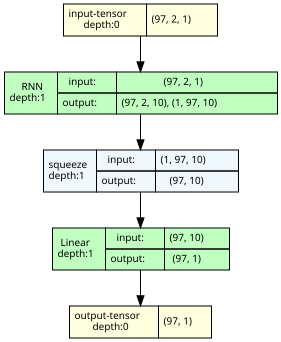

In [54]:
#Grafiquemos las arquitecturas de dos modelos con parámetros diferentes:
input_data = np.random.randn(100)
look_back = 2
X, _ = create_dataset(input_data,look_back=look_back)
X = torch.from_numpy(X).float()
# Una capa RNN recibe entradas de dimensión (Batch,Tiempo,Dimensión). En realidad queremos que los
# retardos sean entendidos como muestras pasadas (Tiempos), por lo tanto agregamos
# una dimensión al final para que el modelo lea los datos como valores pasados de 1
# dimensión.
X = X.unsqueeze(2)
model =  create_rnn_model(num_hidden_neurons = 10)
model_graph = draw_graph(model, input_size=X.shape)
model_graph.visual_graph

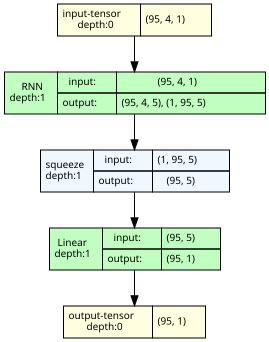

In [40]:
look_back = 4
X, _ = create_dataset(input_data,look_back=look_back)
X = torch.from_numpy(X).float()
X = X.unsqueeze(2)
model =  create_rnn_model(num_hidden_neurons = 5)
model_graph = draw_graph(model, input_size=X.shape)
model_graph.visual_graph

## Ejercicio 3: Experimentar con RNN

Con nuestra función que crea modelos, vamos experimentar variando los dos parámetros:

- número de retrasos
- número de neuronas en la capa oculta

Otras condiciones:
- Vamos a dejar fijo el # de épocas 50.
- Usaremos la métrica MAE (ver [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html))


### Concepto: ciclo de entrenamiento en PyTorch y métrica MAE

El ciclo de entrenamiento en PyTorch sigue siempre el mismo patrón de cuatro pasos:

```python
optimizer.zero_grad()   # 1. Limpiar gradientes del paso anterior
y_pred = model(X)       # 2. Forward pass: calcular predicción
loss = criterion(y_pred, y_true)  # 3. Calcular pérdida
loss.backward()         # 4. Backward pass: calcular gradientes
optimizer.step()        # 5. Actualizar pesos
```

**Función de pérdida MAE (Mean Absolute Error):** en PyTorch se llama `nn.L1Loss()`. Calcula el promedio de los valores absolutos de los errores: `MAE = (1/n) Σ |y_real - ŷ|`. Es más robusta a valores atípicos que el MSE porque no eleva el error al cuadrado.

**Métrica de evaluación:** una vez entrenado el modelo, se usa `mean_absolute_error` de `sklearn.metrics` para calcular el MAE sobre los conjuntos de entrenamiento y prueba. Note que primero hay que llamar a `model.eval()` y usar `torch.no_grad()` (o el método `.detach()`) para obtener predicciones sin calcular gradientes.

**Normalización con `MinMaxScaler`:** la serie se normaliza al rango `[0, 1]` antes de dividirla en entrenamiento y prueba. La división es cronológica (70% train, 30% test), sin mezcla aleatoria, para respetar el orden temporal de la serie.

### Implementación: función `experimentar_rnn`

#### Qué debe programar el estudiante

1. **`trainX, trainY = create_dataset(train, look_back)`** y lo mismo para `test`.
2. **`model = create_rnn_model(num_hidden_neurons=num_hidden_neurons)`**: crear el modelo con el número de neuronas del bucle externo.
3. **`loss = torch.nn.L1Loss()`**: función de pérdida MAE de PyTorch.
4. **Predicciones:** después de entrenar, llamar a `model(trainX)` y `model(testX)` para obtener `trainYPred` y `testYPred`. Como `testY` viene de `create_dataset` como numpy array, usar `.detach().numpy()` solo en las predicciones del modelo.
5. **Errores:** `mean_absolute_error(y_true, y_pred)` de sklearn.
6. **DataFrame:** completar las columnas `'neuronas por capa'`, `'error de entrenamiento'` y `'error de prueba'` con los valores calculados.

In [42]:
def experimentar_rnn(data, look_backs, hidden_neurons):
    """función que realiza experimentos para evaluar una RNN de elman usando
        el error absoluto medio como medida de error

    data: pd.Dataframe, dataset a usar
    look_back: List[int], lista con los número de retrasos a evaluar
    hidden_neurons: List[int], list con el número de neuronas en la capa oculta
    retorna: pd.Dataframe con las siguientes columnas:
        - lags
        - neuronas por capas
        - error de entrenamiento
        - error de prueba
    """
    # Normalizar
    scaler = MinMaxScaler(feature_range=(0, 1))
    dataset = scaler.fit_transform(data)
    # realizar el split
    train_size = int(len(dataset) * 0.7)
    test_size = len(dataset) - train_size
    train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
    resultados = pd.DataFrame()
    idx = 0
    for num_hidden_neurons in hidden_neurons:
        for look_back in look_backs:
            # aplicar la transformación creada antes
            trainX, trainY = create_dataset(train, look_back)
            trainX = torch.from_numpy(trainX).float()
            trainY = torch.from_numpy(trainY).float()
            trainX = trainX.unsqueeze(2)

            testX, testY = create_dataset(test, look_back)
            testX = torch.from_numpy(testX).float()
            testX = testX.unsqueeze(2)

            # creemos el modelo
            model = create_rnn_model(num_hidden_neurons)
            # Defina la función de coste de mean absolute error en PyTorch
            loss = torch.nn.L1Loss()
            optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

            #Entrenaremos el modelo por 50 epocas
            for epoch in range(50):
                model.train()

                optimizer.zero_grad()
                trainYPred = model(trainX)
                trainLoss = loss(trainYPred.squeeze(), trainY)
                trainLoss.backward()
                optimizer.step()

            # Obtener las predicciones del modelo
            model.eval()
            with torch.no_grad():
                trainYPred = model(trainX)
                testYPred = model(testX)
            #Use la métrica de error absoluto medio de sklearn
            #Note que usamos el método detach() para poder usar la función de sklearn
            errorEntrenamiento = mean_absolute_error(trainY.numpy(), trainYPred.squeeze().numpy())
            errorPrueba = mean_absolute_error(testY, testYPred.squeeze().numpy())
            resultados.loc[idx,'lags'] = look_back
            resultados.loc[idx,'neuronas por capa'] = num_hidden_neurons
            resultados.loc[idx,'error de entrenamiento'] = errorEntrenamiento
            resultados.loc[idx,'error de prueba'] = errorPrueba
            idx+=1
            print("termina para", look_back, num_hidden_neurons)

    return (resultados)

**Registra tu solución en línea**

In [43]:
student.submit_task(namespace=globals(), task_id='T3');

Ahora vamos a ver los resultados del experimento:

1. variando los lags dejando las neuronas por capa fijas
2. variando las neuronas y dejando los retrasos fijos

Si la semilla no se ajusta los resultados pueden cambiar debido a la inicialización aleatoria de la red y al tamaño limitado de la serie de tiempo.

### Experimentos: efecto de los retardos y las neuronas

Las siguientes dos celdas ejecutan los experimentos fijando primero el número de neuronas y variando los retardos, y luego fijando los retardos y variando las neuronas. Observe en las gráficas:

- **Efecto de los retardos:** existe un número óptimo de retardos. Pocos retardos implican que el modelo no captura el patrón estacional; demasiados retardos reducen el conjunto de entrenamiento y pueden introducir ruido.
- **Efecto de las neuronas:** más neuronas aumentan la capacidad del modelo, pero también el riesgo de sobreajuste en series cortas como esta.

> **`torch.manual_seed(2)` y `np.random.seed(2)`** garantizan que los resultados sean reproducibles entre ejecuciones.

termina para 3 15
termina para 9 15
termina para 12 15
termina para 24 15
termina para 30 15
termina para 36 15


Text(0.5, 0.98, 'efecto del # retrasos')

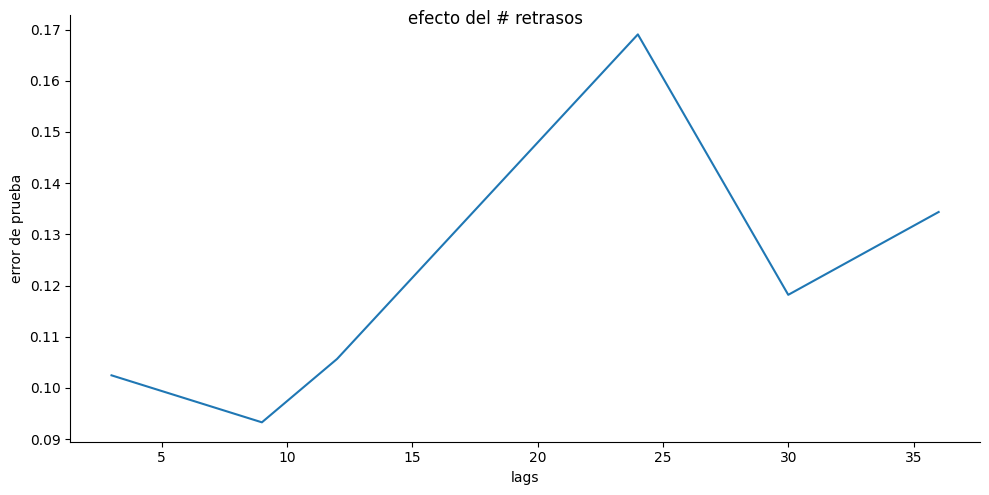

In [45]:
# observa el comportamiento de los lags
import seaborn as sns
import torch.nn as nn
import torch
torch.manual_seed(2)
np.random.seed(2)
resultadosRNN = experimentar_rnn(dataset, look_backs = [3,9,12,24,30,36], hidden_neurons=[15])
# plot
ax1  = sns.relplot(data= resultadosRNN, x= 'lags', y = 'error de prueba', kind = 'line', aspect = 2)
ax1.fig.suptitle('efecto del # retrasos')

termina para 9 5
termina para 9 15
termina para 9 30
termina para 9 60


Text(0.5, 0.98, 'efecto del # neuronas')

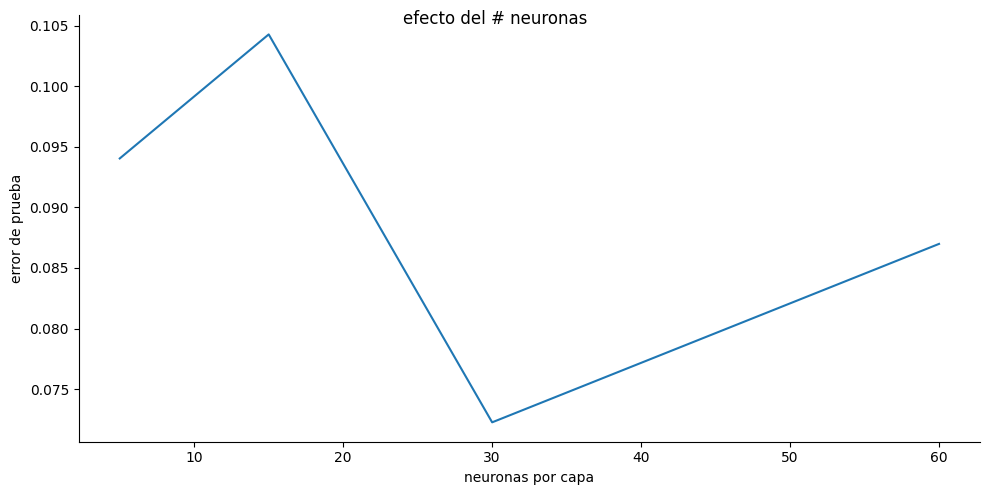

In [46]:
torch.manual_seed(2)
np.random.seed(2)
resultadosRNN = experimentar_rnn(dataset, look_backs = [9], hidden_neurons=[5,15,30,60])
ax2  = sns.relplot(data= resultadosRNN, x= 'neuronas por capa', y = 'error de prueba', kind = 'line', aspect = 2)
ax2.fig.suptitle('efecto del # neuronas')

In [ ]:
#@title Pregunta Abierta
#@markdown ¿Por qué seguir aumentando los tiempos de retardo no implica siempre una mejora en la predicción del modelo?
respuesta = "" #@param {type:"string"}

## Ejercicio 4 - Comparación con MLP

En este ejercicio vamos a resolver el mismo problema, pero con un MLP. Con esto vamos a comparar los resultados obtenidos con la RNN.

Seguiremos las siguientes reglas:
1. Variar el número de retrasos, que corresponden en este caso al número de características en la capa de entrada
2. Usaremos solo una capa oculta y evaluaremos diferente número de neuronas en esta capa
3. El número de épocas también se ajustará a 50
4. Usaremos las misma métrica y función de coste empleadas en el ejercicio anterior.

### Concepto: MLP vs. RNN para series de tiempo

Un MLP también puede resolver este problema: los `look_back` valores pasados se tratan simplemente como características de entrada (sin el concepto de orden temporal). La diferencia fundamental es:

| Aspecto | RNN | MLP |
|---------|-----|-----|
| Manejo del orden temporal | Implícito (estado oculto) | Explícito (posición en el vector de entrada) |
| Parámetros | Compartidos en el tiempo | Independientes por posición |
| Sensibilidad al orden | Alta | Baja |

En teoría, la RNN debería aprovechar mejor el orden temporal. En la práctica, para series cortas y con retardos pequeños, el MLP puede ser competitivo o incluso superior, dado que tiene menos parámetros y se entrena más rápido.

### Implementación: funciones `create_mlp_model` y `experimentar_MLP`

#### `create_mlp_model`
Usar `nn.Sequential` para construir un MLP con:
1. `nn.Linear(look_back, num_hidden_neurons)`: capa de entrada (dimensión `look_back`, no `1` como en la RNN).
2. `nn.ReLU()`: activación de la capa oculta.
3. `nn.Linear(num_hidden_neurons, 1)`: capa de salida con una única neurona (regresión).

#### `experimentar_MLP`
La lógica es idéntica a `experimentar_rnn`, con dos diferencias:
- **No se añade la dimensión extra `.unsqueeze(2)`**: el MLP recibe `(batch, look_back)`, no `(batch, look_back, 1)`.
- **`trainY` se reformatea como columna**: `.reshape(-1, 1)` para que `nn.L1Loss` compare tensores de la misma forma.

Completar los marcadores `...` siguiendo el mismo patrón que en `experimentar_rnn`.

In [47]:
def create_mlp_model(look_back, num_hidden_neurons):
  ''' función que retorna el modelo MLP con una sola capa oculta con función de activación ReLU
      En este caso se puede volver a hacer uso del módulo nn.Sequential de pytorch
      Recordar el ejercicio 4 del laboratorio 4 parte 1.

      Parametros:
        look_back: número de retrasos que serán usados como características de entrada
        num_hidden_neurons: número de neuronas en la capa oculta
      Retorna:
        nn.Module con el modelo MLP

  '''
  return nn.Sequential(
      nn.Linear(look_back, num_hidden_neurons),
      nn.ReLU(),
      nn.Linear(num_hidden_neurons, 1)
  )

def experimentar_MLP(data, look_backs, hidden_neurons):
    """función que realiza experimentos para evaluar una MLP usando
        MAE como medida de error

    data: pd.Dataframe, dataset a usar
    look_back: List[int], lista con los numero de retrasos a evaluar
    hidden_neurons: List[int], list con el numero de neuronas en la capa oculta
    retorna: pd.Dataframe con las siguientes columnas:
        - lags
        - neuronas por capas
        - error de prueba
        - tiempo de entrenamiento
    """
    # we need to normalize the dataset before
    #
    scaler = MinMaxScaler(feature_range=(0, 1))
    dataset = scaler.fit_transform(data)
    # split into train and test sets
    train_size = int(len(dataset) * 0.7)
    test_size = len(dataset) - train_size
    train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
    resultados = pd.DataFrame()
    idx = 0
    for num_hidden_neurons in hidden_neurons:
        for look_back in look_backs:

            trainX, trainY = create_dataset(train, look_back)
            trainX = torch.from_numpy(trainX).float()
            trainY = torch.from_numpy(trainY).float().reshape(-1,1)

            testX, testY = create_dataset(test, look_back)
            testX = torch.from_numpy(testX).float()

           # creemos el modelo MLP
            model = create_mlp_model(look_back, num_hidden_neurons)
            # Defina la función de coste de mean absolute error en PyTorch
            loss = torch.nn.L1Loss()
            optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

            #Entrenaremos el modelo por 50 epocas
            for epoch in range(50):
                model.train()

                optimizer.zero_grad()
                trainYPred = model(trainX)
                trainLoss = loss(trainYPred, trainY)
                trainLoss.backward()
                optimizer.step()

            # Obtener las predicciones del modelo
            model.eval()
            with torch.no_grad():
                trainYPred  = model(trainX)
                testYPred = model(testX)
            #Use la métrica de error absoluto medio de sklearn
            #Note que usamos el método detach() para poder usar la función de sklearn
            errorEntrenamiento = mean_absolute_error(trainY.numpy(), trainYPred.numpy())
            errorPrueba = mean_absolute_error(testY,  testYPred.numpy())
            resultados.loc[idx,'lags'] = look_back
            resultados.loc[idx,'neuronas por capa'] = num_hidden_neurons
            resultados.loc[idx,'error de entrenamiento'] = errorEntrenamiento
            resultados.loc[idx,'error de prueba'] = errorPrueba
            idx+=1
            print("termina para", look_back, num_hidden_neurons)

    return (resultados)

**Registra tu solución en línea**

In [50]:
student.submit_task(namespace=globals(), task_id='T4');

In [48]:
resultadosMLP = experimentar_MLP(dataset, look_backs = [3,9,12,24,30,36], hidden_neurons=[10,20,30])

termina para 3 10
termina para 9 10
termina para 12 10
termina para 24 10
termina para 30 10
termina para 36 10
termina para 3 20
termina para 9 20
termina para 12 20
termina para 24 20
termina para 30 20
termina para 36 20
termina para 3 30
termina para 9 30
termina para 12 30
termina para 24 30
termina para 30 30
termina para 36 30


In [49]:
# para ver los resultados
# en esta instrucción se va resaltar el menor error
resultadosMLP.style.highlight_min(color = 'green', axis = 0, subset = ['error de prueba'])

,lags,neuronas por capa,error de entrenamiento,error de prueba
0,3.000000,10.000000,0.047123,0.131994
1,9.000000,10.000000,0.053984,0.132148
2,12.000000,10.000000,0.025748,0.060519
3,24.000000,10.000000,0.036644,0.072414
4,30.000000,10.000000,0.055041,0.156093
5,36.000000,10.000000,0.022605,0.028217
6,3.000000,20.000000,0.039982,0.104021
7,9.000000,20.000000,0.036546,0.090248
8,12.000000,20.000000,0.026048,0.064742
9,24.000000,20.000000,0.023546,0.043374


## Ejercicio 5 - Construcción de modelo LSTM

En nuestro último ejercicio, vamos a crear una arquitectura de red con una capa LSTM en lugar de una capa RNN. (Ver la documentación de PyTorch sobre este tipo de capas [link](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)).



### Concepto: LSTM y por qué supera a la RNN simple

La **LSTM (Long Short-Term Memory)** fue propuesta por Hochreiter & Schmidhuber (1997) para resolver el problema del gradiente evanescente de las RNN simples. Añade dos vectores de estado: el **estado oculto** `h_t` (memoria a corto plazo) y la **celda** `c_t` (memoria a largo plazo), controlados por tres compuertas:

- **Compuerta de olvido (`f_t`):** decide qué fracción del estado de la celda anterior conservar.
- **Compuerta de entrada (`i_t`):** decide qué nueva información añadir a la celda.
- **Compuerta de salida (`o_t`):** decide qué parte de la celda pasa al estado oculto.

Para este problema, la LSTM puede recordar el patrón estacional de 12 meses incluso cuando `look_back` es grande, mientras que la RNN simple tiende a "olvidar" los valores más lejanos.

**Diferencia en la salida de PyTorch:** `nn.LSTM` retorna `(out, (h_n, c_n))`, no `(out, h_n)`. El estudiante debe desempaquetar correctamente la tupla anidada en el método `forward`.

### Implementación: función `create_lstm_model`

#### Qué debe programar el estudiante

1. **`self.lstm`**: instanciar `nn.LSTM` con `input_size=1`, `hidden_size=num_hidden_neurons` y `batch_first=True`.
2. **`self.linear`**: igual que en la RNN, `nn.Linear(num_hidden_neurons, 1)`.
3. **`forward`**: la capa LSTM retorna `(out, (h_n, c_n))`. Se debe desempaquetar como `out, (h_n, c_n) = self.lstm(x)`, luego usar `h_n.squeeze()` y pasarlo por `self.linear`.

> **Consejo:** una vez que `create_lstm_model` pase el grader, reuse `experimentar_rnn` reemplazando `create_rnn_model` por `create_lstm_model` para comparar los tres modelos (RNN, MLP, LSTM) con la misma función de experimentación.

In [ ]:
#@title Pregunta Abierta
#@markdown ¿Por qué una red LSTM puede ser más adecuada para resolver este problema?
respuesta = "" #@param {type:"string"}

In [51]:
def create_lstm_model(num_hidden_neurons):
    import torch.nn as nn
    """función que crea un modelo LSTM
    La arquitectura de la red LSTM debe estar compuesta de dos capas:
      1. Una capa LSTM (tener en cuenta el número de neuronas ocultas,
         como vamos a modelar una serie temporal unidimensional, el número de características es 1)
      2. Una capa Densa (Linear) de salida

    parametros
      num_hidden_neurons (int): número neuronas en la capa oculta

    retorna nn.Module con la red neuronal
    """

    class LSTM_net(nn.Module):
      def __init__(self, num_hidden_neurons):
          super().__init__()
          self.lstm = nn.LSTM(input_size=1, hidden_size=num_hidden_neurons, batch_first=True)
          self.linear = nn.Linear(in_features=num_hidden_neurons, out_features=1)

      #Este método define el fluje de información a través del modelo
      def forward(self, x):
          _, (h, c) = self.lstm(x)
          x = h.squeeze(0)
          x = self.linear(x)
          return x

    return LSTM_net(num_hidden_neurons)

**Registra tu solución en línea**

In [53]:
student.submit_task(namespace=globals(), task_id='T5');

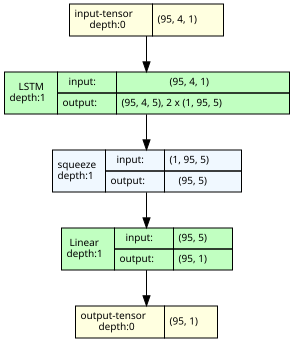

In [52]:
look_back = 4
X, _ = create_dataset(input_data,look_back=look_back)
X = torch.from_numpy(X).float()
X = X.unsqueeze(2)
model =  create_lstm_model(num_hidden_neurons = 5)
model_graph = draw_graph(model, input_size=X.shape)
model_graph.visual_graph

Una vez superada la prueba, pueden usar el modelo creado para realizar experimentación de manera similar al ejercicio 3. La función de experimentación es igual, simplemente es necesario reemplezar la función `create_rnn_model` por la nueva `create_lstm_model` y ejecutar los experimentos.